# dSprites Ablation: Does the Flow Need to Start From the Observed Arm?

The multi-seed simulation says no — at $n_{\mathrm{obs}} = 2000$, pixel SW2 is
$0.0229$ whether the particles start from the observed arm, from
$N(\mu, \Sigma)$, or from $N(0, I)$, and the off-manifold distance (decoded image to
the nearest *valid* bank sprite) is $1.113$ from $N(0,I)$ against $1.125$ from the
observed arm. That is a strong claim resting on aggregate numbers, and a companion
CelebA result showed that summary metrics can be nearly blind to visibly destroyed
samples — so this notebook renders the actual images.

The pipeline is the simulation's, at its reference configuration: disjoint
autoencoder split, cross-fitted DR weights with the estimated continuous-action
ratios clipped at 5, and a Riesz flow under AdamW on standardised latents. Only the
initial particles change; the target support is the logged latents in every run.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from data_utils import load_dsprite_bank, sample_cpme_dsprite_data
from dens_ratio_utils import (crossfit_logging_policy_log_prob,
                              importance_weights_from_logging_log_prob)
from autoencoder_utils import encode_in_batches, snap_to_bank, train_dsprite_ae
from kernel_utils import RBF, RieszKernel
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [2]:
N_OBS, WEIGHT_CLIP = 2000, 5.0
NPZ = "../../data/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"

sprite_bank = load_dsprite_bank(NPZ, cache_path=os.path.join(os.path.dirname(NPZ),
                                                             "heart_sprite_bank_32x32.npy"))
bank_flat = torch.as_tensor(sprite_bank, dtype=torch.float32).reshape(1024, -1).to(device)
data = sample_cpme_dsprite_data(sprite_bank, n_samples=N_OBS, sigma_policy=0.5,
                                policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05, seed=0)

split = torch.randperm(N_OBS, generator=torch.Generator().manual_seed(SEED + 2))
ae_idx, causal_idx = split[:N_OBS // 2], split[N_OBS // 2:]
Y_ae = data["Y_logged"][ae_idx].float().reshape(-1, 1, 64, 64).to(device)
Y_log = data["Y_logged"][causal_idx].float().reshape(-1, 1, 64, 64).to(device)
n_causal = len(causal_idx)

ae, _ = train_dsprite_ae(Y_ae, latent_dim=32, noise_std=0.05, n_iterations=4000,
                         device=device, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
print(f"causal half = {n_causal} images; autoencoder trained on the other {len(ae_idx)}")

causal half = 1000 images; autoencoder trained on the other 1000


In [3]:
X_np = data["X"][causal_idx].numpy()
A_np = data["A_logged"][causal_idx].numpy()
fold_ids = make_crossfit_fold_ids(n_causal, n_folds=5, seed=0)
log_pi0 = crossfit_logging_policy_log_prob(X_np, A_np, fold_ids=fold_ids)
w_hat = np.minimum(importance_weights_from_logging_log_prob(data["target_policy"], X_np,
                                                            A_np, log_pi0), WEIGHT_CLIP)

Z_log = encode_in_batches(ae.encode, Y_log).cpu()
kernel_x, kernel_a = RBF(use_length_scale_heuristic=True), RBF(use_length_scale_heuristic=True)
X_t, A_t = data["X"][causal_idx].double(), data["A_logged"][causal_idx].double()
K_x, K_a = kernel_x(X_t), kernel_a(A_t)
rng = np.random.default_rng(0)
K_a_target = torch.zeros(n_causal, n_causal, dtype=torch.float64)
for _ in range(8):
    K_a_target += kernel_a(A_t, torch.as_tensor(data["target_policy"].sample(X_np, rng),
                                                dtype=torch.float64))
K_a_target /= 8
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_log[train, 0].double(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target,
                                torch.as_tensor(w_hat, dtype=torch.float64),
                                fold_ids, fold_lambdas)
print(f"sum(v) = {float(v_dr.sum()):.3f}")

sum(v) = 0.989


## 2. Three Flows, Three Starting Clouds

The target support is the logged latents throughout; only the particles change.
$N(0, I)$ and $N(\mu, \Sigma)$ are drawn in the standardised latent space, the
coordinates the flow operates in.

In [4]:
latent_mean = Z_log.mean(dim=0, keepdim=True)
latent_std = Z_log.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: ((z - latent_mean) / latent_std).float()
from_flow = lambda z: z.cpu().float() * latent_std + latent_mean
flow_target = to_flow(Z_log).to(device)


def gaussian_init(reference, n_particles, mode, generator):
    "N(0, I), or the reference sample's empirical N(mu, Sigma) via its centred data matrix."
    n, dim = reference.shape
    if mode == "normal":
        return torch.randn(n_particles, dim, generator=generator, device=reference.device)
    mean = reference.mean(dim=0, keepdim=True)
    weights = torch.randn(n_particles, n, generator=generator, device=reference.device)
    return mean + weights @ (reference - mean) / (n - 1) ** 0.5


def decode(particles):
    with torch.no_grad():
        return torch.cat([ae.decode(from_flow(particles[i:i + 256]).to(device))
                          for i in range(0, len(particles), 256)]).reshape(len(particles), -1)


runs = {}
for init in ("observed", "moment", "normal"):
    start = (flow_target.clone() if init == "observed" else
             gaussian_init(flow_target, n_causal, init,
                           torch.Generator(device=device).manual_seed(SEED + 3)))
    flowed, info = adamw_riesz_flow(start, flow_target,
                                    target_weights=v_dr.float().to(device), sliced=False,
                                    n_iterations=2000, learning_rate=0.01,
                                    warmup_steps=100, verbose=False)
    runs[init] = {"start": start, "flowed": flowed,
                  "start_images": decode(start), "images": decode(flowed)}
    offmani = snap_to_bank(runs[init]["images"], bank_flat)[1]
    print(f"{init:9s} loss {info['loss'][0]:6.2f} -> {info['loss'][-1]:5.2f}   "
          f"transport {(flowed - start).norm(dim=1).mean():6.2f}   "
          f"off-manifold median {float(offmani.median()):.2f}")

observed  loss   5.83 ->  3.83   transport   6.84   off-manifold median 2.19


moment    loss   5.81 ->  3.76   transport   8.28   off-manifold median 2.17


normal    loss   5.82 ->  3.80   transport   9.01   off-manifold median 2.18


## 3. The Images

Top row of each block: the decoded **starting** particles. Bottom row: after the flow.
The oracle row is a fresh interventional draw. If the flow truly forgets its
initialisation, the bottom rows should be indistinguishable across blocks — clean
sprites — even where the top row is pure noise.

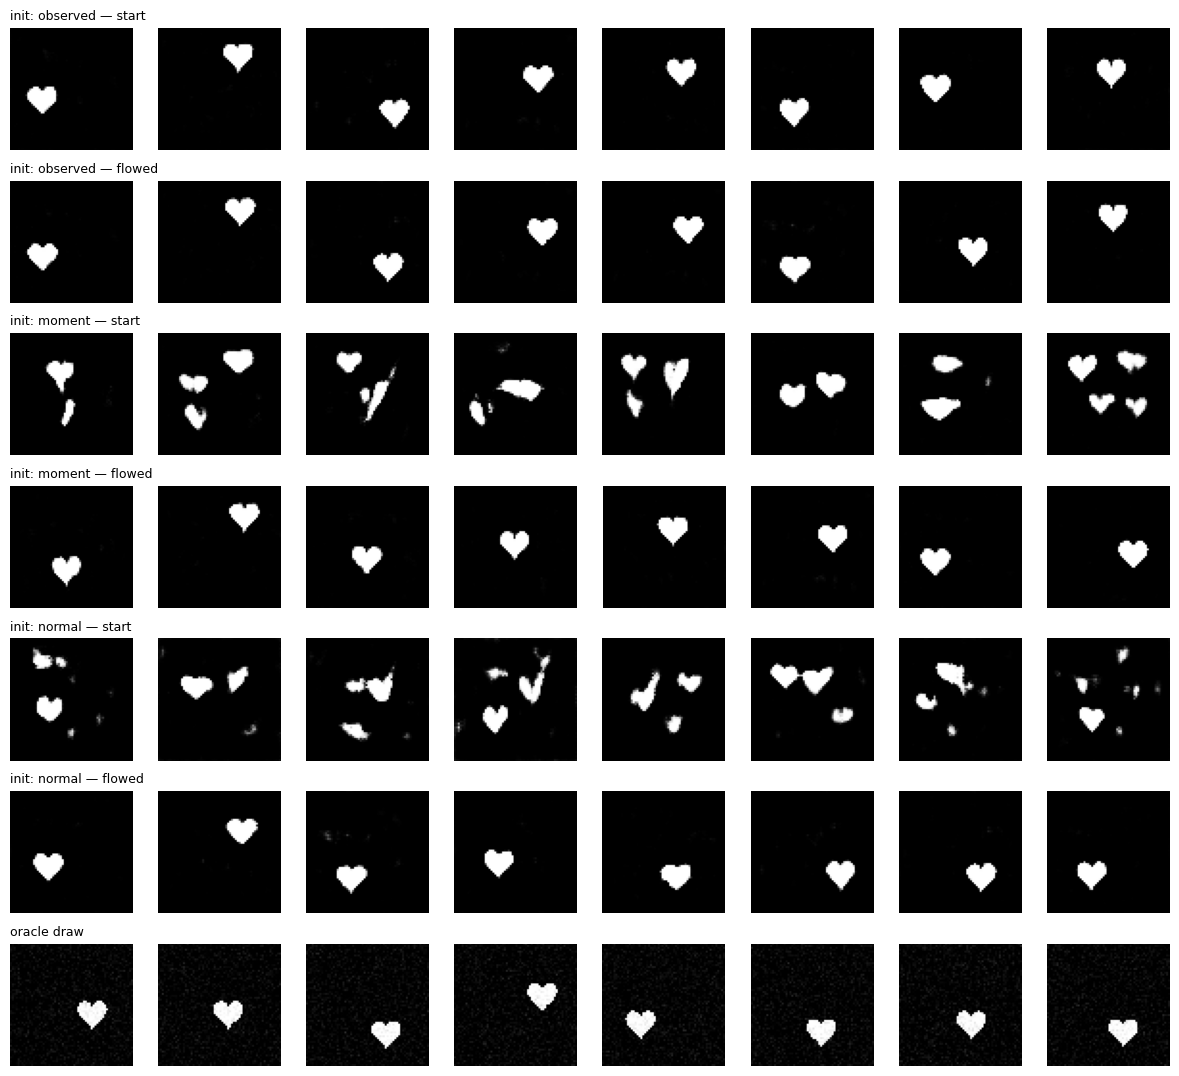

In [5]:
oracle = data["Y_target"][causal_idx].float()
n_show, idx = 8, 40
blocks = [(f"init: {init}", runs[init]["start_images"], runs[init]["images"])
          for init in ("observed", "moment", "normal")]

fig, axes = plt.subplots(2 * len(blocks) + 1, n_show,
                         figsize=(1.5 * n_show, 1.55 * (2 * len(blocks) + 1)))
for b, (label, start_images, flow_images) in enumerate(blocks):
    for j in range(n_show):
        axes[2 * b, j].imshow(start_images[idx + j].reshape(64, 64).cpu(), cmap="gray",
                              vmin=0, vmax=1)
        axes[2 * b + 1, j].imshow(flow_images[idx + j].reshape(64, 64).cpu(), cmap="gray",
                                  vmin=0, vmax=1)
    axes[2 * b, 0].set_title(f"{label} — start", fontsize=9, loc="left")
    axes[2 * b + 1, 0].set_title(f"{label} — flowed", fontsize=9, loc="left")
for j in range(n_show):
    axes[-1, j].imshow(oracle[idx + j].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
axes[-1, 0].set_title("oracle draw", fontsize=9, loc="left")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()

## 4. The Position Law

The intervention shifts where the sprite sits. Each panel snaps the decoded particles
to the nearest bank sprite and plots the resulting positions against the oracle.

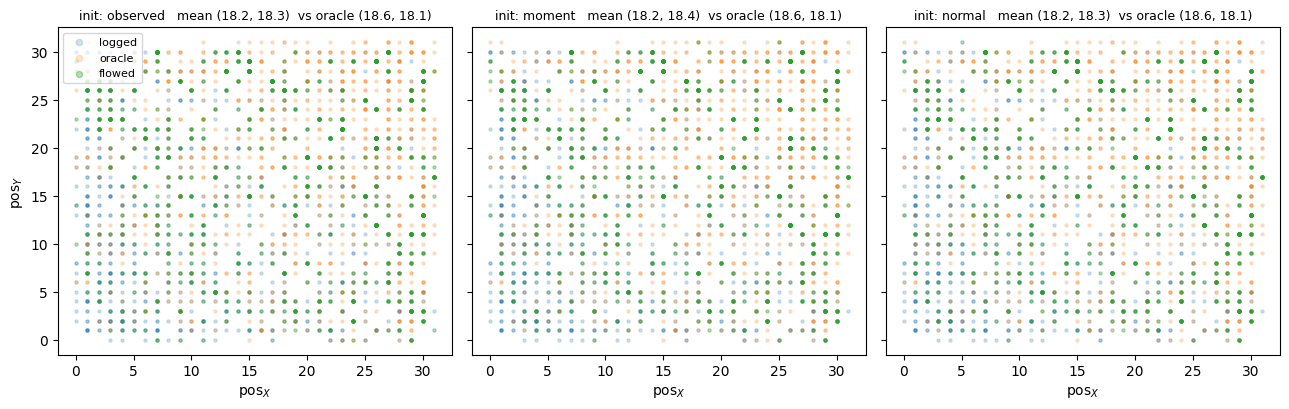

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
oracle_pos = data["pos_target"][causal_idx].double()
logged_pos = data["pos_logged"][causal_idx].double()
for ax, init in zip(axes, ("observed", "moment", "normal")):
    flow_pos = snap_to_bank(runs[init]["images"], bank_flat)[0].cpu().float()
    ax.scatter(*logged_pos.T, s=5, alpha=0.2, label="logged")
    ax.scatter(*oracle_pos.T, s=5, alpha=0.2, label="oracle")
    ax.scatter(*flow_pos.T, s=5, alpha=0.35, label="flowed")
    ax.set_title(f"init: {init}   mean ({flow_pos[:, 0].mean():.1f}, "
                 f"{flow_pos[:, 1].mean():.1f})  vs oracle "
                 f"({oracle_pos[:, 0].mean():.1f}, {oracle_pos[:, 1].mean():.1f})",
                 fontsize=9)
    ax.set_xlabel(r"$\mathrm{pos}_X$")
axes[0].set_ylabel(r"$\mathrm{pos}_Y$")
axes[0].legend(fontsize=8, markerscale=2)
fig.tight_layout()
plt.show()

## 5. Metrics

In [7]:
energy_kernel = RieszKernel()
references = [sample_cpme_dsprite_data(sprite_bank, n_samples=n_causal, sigma_policy=0.5,
                                       policy_shift=0.2, pos_gain=3.0, pixel_noise=0.05,
                                       seed=100000 + j)["Y_target"].float().to(device)
              for j in range(5)]
clean_floor = bank_flat[(oracle_pos.long()[:, 0] * 32 + oracle_pos.long()[:, 1])]

print(f"{'sample':22s} {'energy':>9s} {'SW2':>9s} {'off-manifold':>13s}")
rows = [("logged (no flow)", data["Y_logged"][causal_idx].float().to(device))]
rows += [(f"flow from {init}", runs[init]["images"]) for init in ("observed", "moment", "normal")]
rows += [("clean-sprite floor", clean_floor)]
for name, images in rows:
    images = images.to(device)
    energy = np.mean([float(squared_mmd(energy_kernel, images.double(), r.double()))
                      for r in references])
    sw2 = np.mean([float(sliced_wasserstein(images, r, p=2, seed=0)) for r in references])
    offmani = float(snap_to_bank(images, bank_flat)[1].median())
    print(f"{name:22s} {energy:9.4f} {sw2:9.4f} {offmani:13.2f}")

sample                    energy       SW2  off-manifold


logged (no flow)          0.6413    0.0525          3.20


flow from observed        0.1203    0.0256          2.19


flow from moment          0.1218    0.0257          2.17


flow from normal          0.1212    0.0257          2.18


clean-sprite floor        0.0459    0.0163          0.00


## Summary

**The images confirm the simulation's claim.** Starting from $N(0, I)$ the decoded
particles are fragmented multi-blob garbage — several partial hearts, smears, no
valid sprite anywhere — and after 2000 iterations they are single clean hearts,
visually indistinguishable from the observed-init output. The $N(\mu, \Sigma)$ start
behaves the same way. This is a real reconstruction from noise, not a metric
artefact.

**Every summary quantity agrees.** Energy distance $0.1203 / 0.1218 / 0.1212$ and
SW2 $0.0256 / 0.0257 / 0.0257$ for observed / $N(\mu,\Sigma)$ / $N(0,I)$, against a
logged baseline of $0.6413 / 0.0525$ and a clean-sprite floor of $0.0459 / 0.0163$.
The off-manifold distance — decoded image to the nearest *valid* bank sprite, an
independent check that owes nothing to sliced projections — is $2.19 / 2.17 / 2.18$
against $3.20$ for the logged images. The position law lands on the oracle from all
three starts (mean $(18.2, 18.3)$ vs oracle $(18.6, 18.1)$).

**Why this differs from CelebA.** The companion CelebA ablation found the opposite:
there, all inits matched in latent SW2 while the decoded images degraded $2.3\times$,
because a $32 \times 32 \times 4$ VAE latent is a $4096$-dimensional space whose
decoder collapses under a $3\%$ positional error. Here the latent is $32$-dimensional
and the outcome manifold is $1024$ discrete sprite positions — a target the flow can
actually reach from anywhere. The lesson is not "initialisation does not matter" but
that its cost scales with how thin the decoder's valid set is relative to the space
the flow explores.

**Caveat worth keeping.** The flow still sits $2.6\times$ above the clean-sprite floor
in energy distance from every init, so "insensitive to initialisation" is a statement
about the *gap between inits*, not about closing the gap to the oracle.

**CORRECTION (2026-09-12).** Everything above is measured at the END of the flow, and
that is the whole limitation of this notebook: scored against the ITERATION at which
the flow is stopped, this design does *not* treat the three inits alike. Under the
identical pipeline with snapshots, pixel SW2 at iteration 100 is $0.0453$ from the
observed start against $0.0746$ ($N(\mu,\Sigma)$) and $0.0641$ ($N(0,I)$), all three
converging to a common $0.0254$ by iteration 500. So "the flow forgets its
initialisation" holds only asymptotically; the observational start is worth a factor
of $1.4$–$1.6$ at a hundred iterations. The multi-factor companion
(`dSprites_MultiFactor_Init_Ablation`) makes the same point with a larger gap
($2.3$–$3.0\times$) and adds the content-preservation axis this design cannot
express. Initialisation should be judged against a compute budget, never at
convergence alone.